### Artificial Neurons(model)

In [4]:
import torch
import torch.nn as nn

neuron = nn.Linear(1, 1)

x = torch.tensor([[3.0]])

model = nn.Sequential(
    nn.Linear(1, 8),
    nn.ReLU(),
    nn.Linear(8, 1)
)

print(model)

print(neuron(x))

Sequential(
  (0): Linear(in_features=1, out_features=8, bias=True)
  (1): ReLU()
  (2): Linear(in_features=8, out_features=1, bias=True)
)
tensor([[0.2338]], grad_fn=<AddmmBackward0>)


### Error Function

In [7]:
import torch
import torch.nn as nn

loss_fn = nn.MSELoss()

prediction = torch.tensor([8.0])

actual = torch.tensor([10.0])

loss = loss_fn(prediction, actual)

print(loss)

tensor(4.)


### single linear layer

In [8]:
import torch
import torch.nn as nn

relu = nn.ReLU()

x = torch.tensor([-3., 2., 5.])

print(relu(x))

tensor([0., 2., 5.])


### More Activation Functions(Sigmoid, Tanh, ReLU)

In [9]:
import torch
import torch.nn as nn

sigmoid = nn.Sigmoid()
tanh = nn.Tanh()
relu = nn.ReLU()

print(relu(torch.tensor([-2.,0.,2.])))
print(tanh(torch.tensor([-2.,0.,2.])))
print(sigmoid(torch.tensor([-2.,0.,2.])))

tensor([0., 0., 2.])
tensor([-0.9640,  0.0000,  0.9640])
tensor([0.1192, 0.5000, 0.8808])


### Example
Predictions improve  
Loss decreases  
Weights and biases are updated  

In [12]:
import torch
import torch.nn as nn

model = nn.Linear(1,1)

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.01
)

loss_fn = nn.MSELoss()

X = torch.tensor([[1.],[2.],[3.]])
y = torch.tensor([[2.],[4.],[6.]])

for epoch in range(100):
    prediction = model(X)
    loss = loss_fn(prediction, y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

print(model(torch.tensor([[4.]])))

tensor([[7.8353]], grad_fn=<AddmmBackward0>)


### Mini Example

In [13]:
import torch
import torch.nn as nn

# Dataset
X = torch.tensor([[1.],[2.],[3.],[4.]], dtype=torch.float32)
y = torch.tensor([[2.],[4.],[6.],[8.]], dtype=torch.float32)

# Neural Network
model = nn.Sequential(
    nn.Linear(1,8),
    nn.ReLU(),
    nn.Linear(8,1)
)

# Loss
loss_fn = nn.MSELoss()

# Optimizer
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

# Training
for epoch in range(300):
    prediction = model(X)
    loss = loss_fn(prediction, y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

print("Prediction for 5 =", model(torch.tensor([[5.]])))

Prediction for 5 = tensor([[9.9684]], grad_fn=<AddmmBackward0>)


### PyTorch nn Module

In [14]:
import torch
import torch.nn as nn

class MyModel(nn.Module):

    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(1,1)

    def forward(self, x):
        return self.linear(x)

model = MyModel()

x = torch.tensor([[5.0]])

print(model(x))      # Calls forward() automatically

tensor([[-1.1300]], grad_fn=<AddmmBackward0>)


In [ ]:
Returning to the Linear Model
model = nn.Linear(1,1)

Replacing the Linear Model
model = nn.Sequential(
    nn.Linear(1,8),
    nn.ReLU(),
    nn.Linear(8,1)
)

### Complete Code

In [15]:
import torch
import torch.nn as nn

# --------------------------
# Dataset
# --------------------------
X = torch.tensor([
    [1.0],
    [2.0],
    [3.0],
    [4.0]
], dtype=torch.float32)

y = torch.tensor([
    [2.0],
    [4.0],
    [6.0],
    [8.0]
], dtype=torch.float32)

# --------------------------
# Custom Model (nn.Module)
# --------------------------
class HousePriceNet(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(1,8),
            nn.ReLU(),
            nn.Linear(8,1)
        )

    def forward(self, x):
        return self.network(x)

# Create Model
model = HousePriceNet()

# --------------------------
# Model Architecture
# --------------------------
print(model)

# --------------------------
# Parameters
# --------------------------
print("\nModel Parameters")
for name, param in model.named_parameters():
    print(name, param.shape)

print("\nTotal Parameters:",
      sum(p.numel() for p in model.parameters()))

# --------------------------
# Loss Function
# --------------------------
loss_fn = nn.MSELoss()

# --------------------------
# Optimizer
# --------------------------
optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.01
)

# --------------------------
# Training
# --------------------------
epochs = 500

for epoch in range(epochs):

    # Forward Pass
    prediction = model(X)

    # Compute Loss
    loss = loss_fn(prediction, y)

    # Clear Gradients
    optimizer.zero_grad()

    # Backpropagation
    loss.backward()

    # Update Parameters
    optimizer.step()

    if (epoch + 1) % 100 == 0:
        print(f"Epoch {epoch+1}, Loss = {loss.item():.6f}")

# --------------------------
# Prediction
# --------------------------
test = torch.tensor([[5.0]])

print("\nPrediction for Input = 5")
print(model(test))

HousePriceNet(
  (network): Sequential(
    (0): Linear(in_features=1, out_features=8, bias=True)
    (1): ReLU()
    (2): Linear(in_features=8, out_features=1, bias=True)
  )
)

Model Parameters
network.0.weight torch.Size([8, 1])
network.0.bias torch.Size([8])
network.2.weight torch.Size([1, 8])
network.2.bias torch.Size([1])

Total Parameters: 25
Epoch 100, Loss = 0.007279
Epoch 200, Loss = 0.000688
Epoch 300, Loss = 0.000063
Epoch 400, Loss = 0.000006
Epoch 500, Loss = 0.000001

Prediction for Input = 5
tensor([[9.9988]], grad_fn=<AddmmBackward0>)


## Full Code

X shape: torch.Size([100, 1])
Y shape: torch.Size([100, 1])

Neuron:
Linear(in_features=1, out_features=1, bias=True)

Model:
Sequential(
  (0): Linear(in_features=1, out_features=8, bias=True)
  (1): ReLU()
  (2): Linear(in_features=8, out_features=1, bias=True)
)
Epoch  200 | Loss: 0.276253
Epoch  400 | Loss: 0.099097
Epoch  600 | Loss: 0.076484
Epoch  800 | Loss: 0.064477
Epoch 1000 | Loss: 0.053223
Epoch 1200 | Loss: 0.043343
Epoch 1400 | Loss: 0.035217
Epoch 1600 | Loss: 0.028852
Epoch 1800 | Loss: 0.023817
Epoch 2000 | Loss: 0.019980

PARAMETERS
0.weight: shape=torch.Size([8, 1])
0.bias: shape=torch.Size([8])
2.weight: shape=torch.Size([1, 8])
2.bias: shape=torch.Size([1])

Total parameters: 25


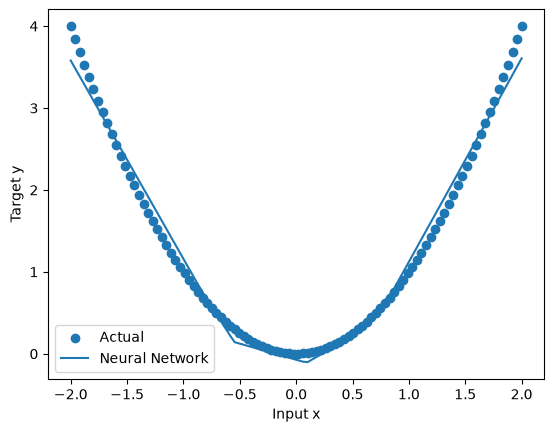

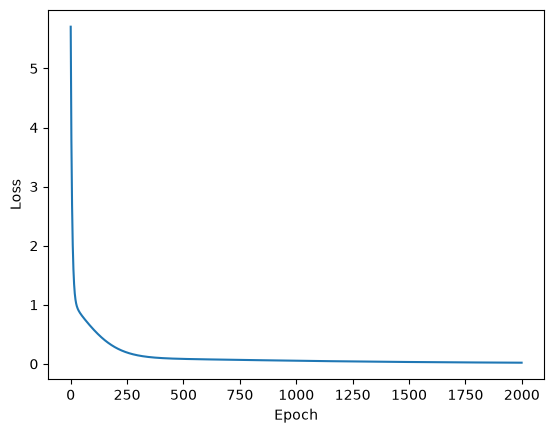

In [2]:
# ============================================
# CHAPTER 6
# USING A NEURAL NETWORK TO FIT THE DATA
# ============================================

import torch
import torch.nn as nn
import matplotlib.pyplot as plt


# ============================================
# 1. CREATE DATA
# ============================================

torch.manual_seed(42)

# 100 values from -2 to +2
x = torch.linspace(
    -2,
    2,
    100
).reshape(-1, 1)

# Nonlinear target
y = x ** 2


print("X shape:", x.shape)
print("Y shape:", y.shape)


# ============================================
# 2. ARTIFICIAL NEURON
# ============================================

neuron = nn.Linear(
    1,
    1
)

print("\nNeuron:")
print(neuron)


# ============================================
# 3. MULTILAYER NEURAL NETWORK
# ============================================

model = nn.Sequential(

    # First layer
    nn.Linear(
        1,
        8
    ),

    # Nonlinearity
    nn.ReLU(),

    # Output layer
    nn.Linear(
        8,
        1
    )
)

print("\nModel:")
print(model)


# ============================================
# 4. LOSS FUNCTION
# ============================================

loss_fn = nn.MSELoss()


# ============================================
# 5. OPTIMIZER
# ============================================

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.01
)


# ============================================
# 6. TRAINING
# ============================================

epochs = 2000

loss_history = []

for epoch in range(epochs):

    # Forward pass
    prediction = model(x)

    # Calculate error
    loss = loss_fn(
        prediction,
        y
    )

    # Clear old gradients
    optimizer.zero_grad()

    # Calculate gradients
    loss.backward()

    # Update parameters
    optimizer.step()

    # Save loss
    loss_history.append(
        loss.item()
    )

    if (epoch + 1) % 200 == 0:

        print(
            f"Epoch {epoch + 1:4d} | "
            f"Loss: {loss.item():.6f}"
        )


# ============================================
# 7. INSPECT PARAMETERS
# ============================================

print("\nPARAMETERS")

for name, parameter in model.named_parameters():

    print(
        f"{name}: "
        f"shape={parameter.shape}"
    )


# ============================================
# 8. COUNT PARAMETERS
# ============================================

total_parameters = sum(
    p.numel()
    for p in model.parameters()
)

print(
    "\nTotal parameters:",
    total_parameters
)


# ============================================
# 9. PREDICTION
# ============================================

model.eval()

with torch.no_grad():

    prediction = model(x)


# ============================================
# 10. VISUALIZE FIT
# ============================================

plt.scatter(
    x.numpy(),
    y.numpy(),
    label="Actual"
)

plt.plot(
    x.numpy(),
    prediction.numpy(),
    label="Neural Network"
)

plt.xlabel("Input x")
plt.ylabel("Target y")

plt.legend()

plt.show()


# ============================================
# 11. VISUALIZE LOSS
# ============================================

plt.plot(
    loss_history
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.show()